In [1]:
!pip install python-docx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 1.8 MB/s eta 0:00:00


In [2]:
import docx

# Open and read the document
doc_path = '/content/STUDENT PROCEDURAL MANUAL - Lab 4.docx'
doc = docx.Document(doc_path)

# Print the text paragraphs
for i, paragraph in enumerate(doc.paragraphs):
    if paragraph.text.strip():
        print(f"[{i}]: {paragraph.text}")

[4]: College of Computer Science and Information Technology
[5]: تامولعملا ةينقتو بساحلا مولع ةيلك
[33]: DEPARTMENT OF COMPUTER ENGINEERING
[52]: ARTI 404 – Image Processing
[55]: STUDENT PROCEDURAL MANUAL Lab 4
[59]: 2025 - 2026
[63]: Practical Session Plan
[67]: 1- Session Outcomes
[69]: Outcome#2: Write a program that implements fundamental image processing algorithms.
[71]: 2- Tool(s)/Software	.
[72]: •	Python 3
[73]: •	Anaconda
[74]: •	IDE for Python: Jupyter, Spyder.
[75]: •	Libraries: OpenCV, NumPy, Pillow, Skimage, Matplotlib.
[79]: 3- Procedural steps (Tasks)
[82]: Task#1: Thresholding
[83]: Step#1: Apply thresholding with a fixed threshold on an image:
[84]: In image processing, thresholding is a common technique used to separate objects or regions in an image based on their pixel intensities. It involves converting a grayscale or color image into a binary image, where pixels are classified as either "foreground" or "background" based on a specified threshold value.
[85]: The

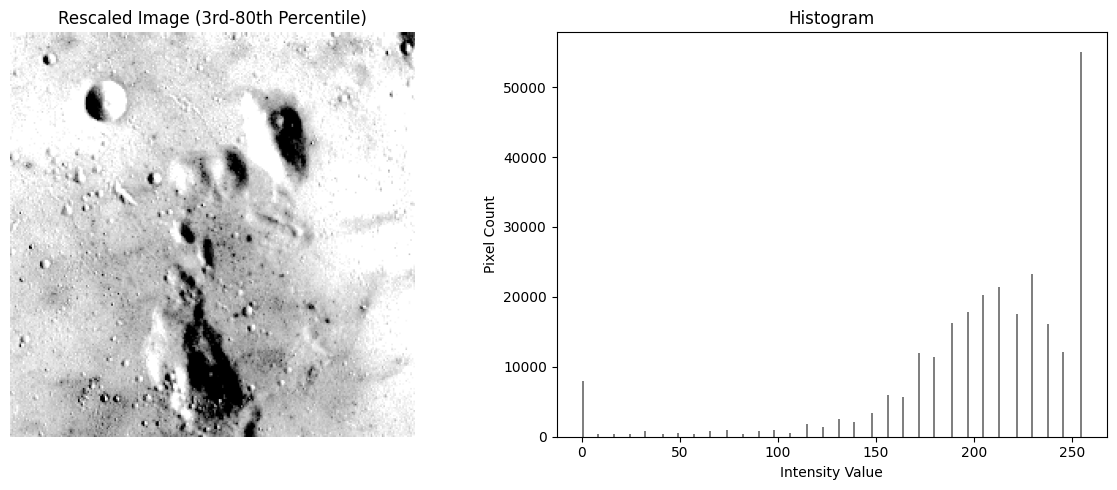

In [3]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, exposure

# Load moon image
moon = data.moon()

# Find 3rd and 80th percentiles
p3, p80 = np.percentile(moon, (3, 80))

# Rescale intensity
img_rescaled = exposure.rescale_intensity(moon, in_range=(p3, p80))

# Plot rescaled image
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_rescaled, cmap='gray')
axes[0].set_title('Rescaled Image (3rd-80th Percentile)')
axes[0].axis('off')

# Plot histogram
axes[1].hist(img_rescaled.ravel(), bins=256, range=(0, 255), color='gray')
axes[1].set_title('Histogram')
axes[1].set_xlabel('Intensity Value')
axes[1].set_ylabel('Pixel Count')

plt.tight_layout()
plt.show()

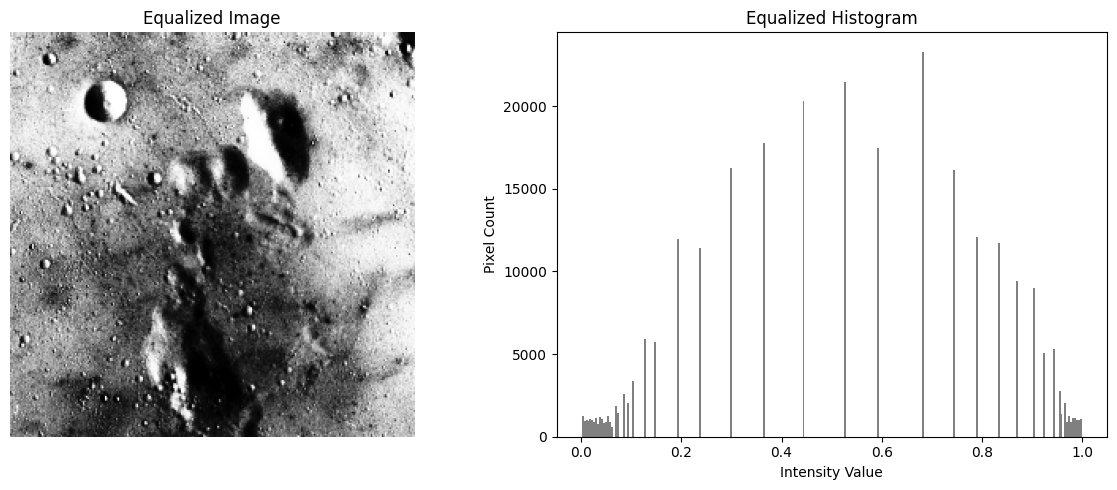

In [4]:
# Equalize moon image histogram
img_equalized = exposure.equalize_hist(moon)

# Plot equalized image
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_equalized, cmap='gray')
axes[0].set_title('Equalized Image')
axes[0].axis('off')

# Plot equalized histogram
axes[1].hist(img_equalized.ravel(), bins=256, color='gray')
axes[1].set_title('Equalized Histogram')
axes[1].set_xlabel('Intensity Value')
axes[1].set_ylabel('Pixel Count')

plt.tight_layout()
plt.show()

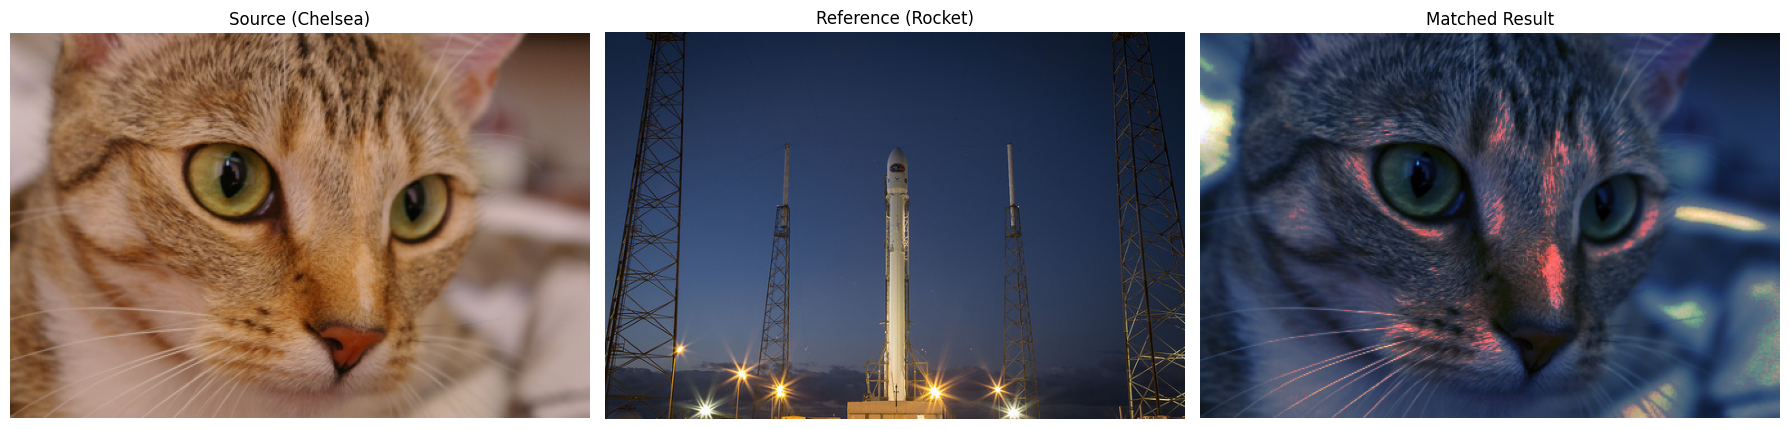

In [5]:
from skimage.exposure import match_histograms

# Load source chelsea and reference rocket images
source = data.chelsea()
reference = data.rocket()

# match histograms across channels
matched = match_histograms(source, reference, channel_axis=-1)

# matching results
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(source)
axes[0].set_title('Source (Chelsea)')
axes[0].axis('off')

axes[1].imshow(reference)
axes[1].set_title('Reference (Rocket)')
axes[1].axis('off')

axes[2].imshow(matched)
axes[2].set_title('Matched Result')
axes[2].axis('off')

plt.tight_layout()
plt.show()